# Free-shipping threshold A/B test — walkthrough
**Simulated data** (known ground truth). This notebook re-computes the key results live with the toolkit in `src/abtools.py`; the full pipeline, Monte Carlo validation and memo are in the repo.

**Feature:** free-shipping threshold at checkout, $100 → $75.
**Decision:** roll out to everyone, roll out to a segment, or keep $100.
**Decision metric:** margin per visitor (conversion × margin per order). **Guardrail:** return rate.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from abtools import srm_test, smd, compare, welch, cuped_adjust, bootstrap_diff, calibrate_boundaries
df = pd.read_csv("../data/experiment.csv.gz")
power = json.load(open("../results/power.json"))
print(f"{len(df):,} logged users; {df.groupby('variant').size().to_dict()}")
df.head(3)

394,724 logged users; {0: 200013, 1: 194711}


,user_id,arrival_day,dow,device,is_new,source,app_old,pre_spend_90d,pre_orders_90d,variant,purchased,basket,net_rev,ship_cost,returned,margin,items
0,0,7,0,desktop,1,organic,0,0.00,0,1,0,0.0,0.0,0.0,0,0.0,0
1,1,2,2,mobile,0,direct,0,92.34,1,1,0,0.0,0.0,0.0,0,0.0,0
2,2,10,3,desktop,0,paid,0,0.00,0,0,0,0.0,0.0,0.0,0,0.0,0


## 1. Plan: what can a 14-day test detect?
From a separate historical sample (never from the experiment):

baseline conversion 3.24%, margin/visitor $1.06 (sd $8.00)
MDE at 200K/arm: margin/visitor 6.7% relative, conversion 4.9% relative


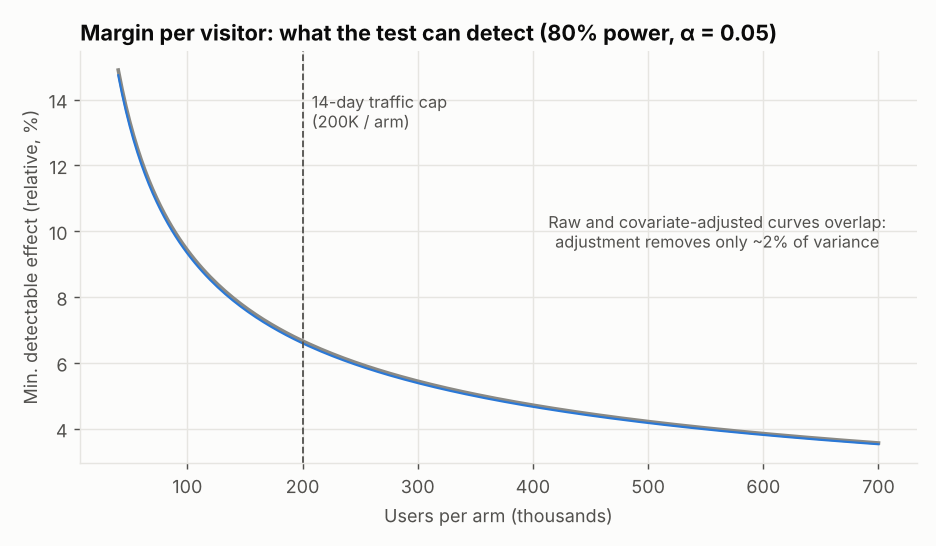

In [2]:
b, a = power["baseline"], power["achieved"]
print(f"baseline conversion {b['conv']:.2%}, margin/visitor ${b['margin_per_visitor']:.2f} (sd ${b['margin_sd']:.2f})")
print(f"MDE at 200K/arm: margin/visitor {a['mde_margin_raw']:.1%} relative, conversion {a['mde_conv_rel']:.1%} relative")
Image("../figures/power_curve.png")

## 2. Validity first: sample ratio mismatch

In [3]:
t, c = df[df.variant == 1], df[df.variant == 0]
print("SRM, all users:   ", srm_test(len(t), len(c)))
m = df[df.device == "mobile"]
for flag, g in m.groupby("app_old"):
    r = srm_test((g.variant == 1).sum(), (g.variant == 0).sum())
    print(f"mobile, app_old={flag}: share treated {r['share_treat']:.3f}, p={r['p']:.1e}")

SRM, all users:    {'chi2': 71.2173670716754, 'p': 3.1995930511605154e-17, 'n_treat': 194711, 'n_ctrl': 200013, 'share_treat': 0.49328391483669604}


mobile, app_old=0: share treated 0.499, p=2.6e-01
mobile, app_old=1: share treated 0.416, p=4.0e-191


The mismatch is confined to old-app mobile users. What does ignoring it cost?

In [4]:
clean = df[df.app_old == 0]
naive = compare(t.purchased.values.astype(float), c.purchased.values.astype(float))
fixed = compare(clean[clean.variant == 1].purchased.values.astype(float), clean[clean.variant == 0].purchased.values.astype(float))
print(f"conversion lift, bug ignored: {naive['rel']:+.1%}   after excluding old-app: {fixed['rel']:+.1%}  (CI {fixed['rel_lo']:+.1%} to {fixed['rel_hi']:+.1%})")
print("SRM after exclusion:", srm_test((clean.variant == 1).sum(), (clean.variant == 0).sum())['p'])

conversion lift, bug ignored: +8.7%   after excluding old-app: +5.7%  (CI +2.1% to +9.4%)
SRM after exclusion: 0.8024273746496442


## 3. Does the pipeline have the right false-positive rate? (200 A/A splits of control users)

A/A false-positive rate (margin/visitor): 0.05


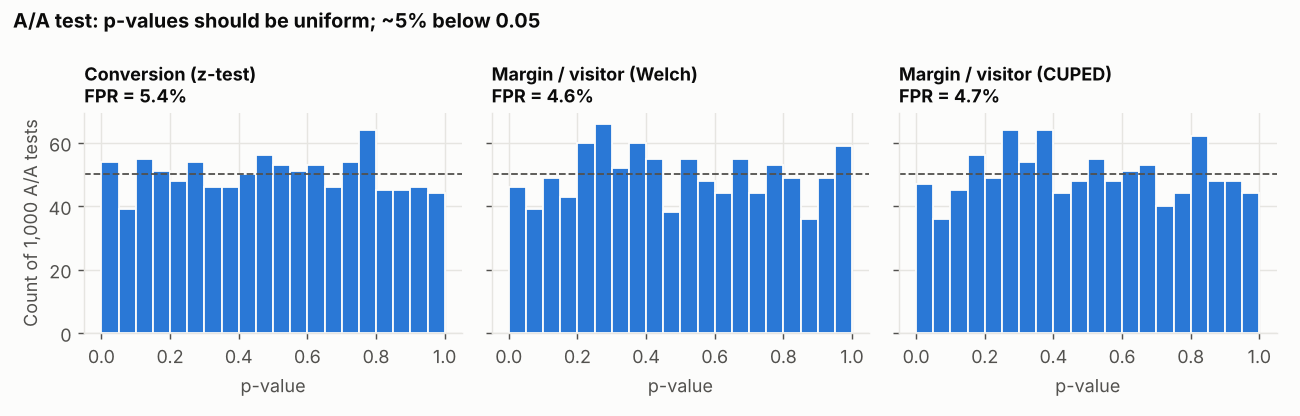

In [5]:
rng = np.random.default_rng(0)
ctrl = clean[clean.variant == 0]
y = ctrl.margin.values
ps = []
for _ in range(200):
    mask = rng.random(len(y)) < 0.5
    ps.append(welch(y[mask], y[~mask])["p"])
print("A/A false-positive rate (margin/visitor):", np.mean(np.array(ps) < 0.05))
Image("../figures/aa_pvalues.png")

## 4. Primary metric: margin per visitor, five ways

In [6]:
t, c = clean[clean.variant == 1], clean[clean.variant == 0]
cap = power["baseline"]["winsor_cap"]
base = c.margin.mean()
rows = {"Welch": welch(t.margin.values, c.margin.values),
        "Winsorised": welch(t.margin.clip(upper=cap).values, c.margin.clip(upper=cap).values),
        "Bootstrap": bootstrap_diff(t.margin.values, c.margin.values, B=1000, seed=1)}
yadj, diag = cuped_adjust(clean.margin.values, clean.pre_spend_90d.values)
mask = (clean.variant == 1).values
rows["CUPED"] = welch(yadj[mask], yadj[~mask])
for k, v in rows.items():
    print(f"{k:11s} {v['diff']/base:+.2%}  [{v['lo']/base:+.2%}, {v['hi']/base:+.2%}]")
print(f"CUPED: corr {diag['corr']:.2f}, variance reduction {diag['var_reduction']:.1%}  <- small: rare purchases, 40% new users")

Welch       -0.68%  [-5.56%, +4.21%]
Winsorised  -0.10%  [-4.59%, +4.40%]
Bootstrap   -0.68%  [-5.19%, +4.35%]
CUPED       -0.05%  [-4.88%, +4.79%]
CUPED: corr 0.15, variance reduction 2.2%  <- small: rare purchases, 40% new users


**Reading:** conversion is clearly up, margin per visitor is inconclusive. That matches the design doc's warning that 14 days is under-powered for margin.

## 5. Peeking: why you cannot stop at the first p < 0.05

{'fixed_day14': 0.051, 'peek_daily_naive': 0.219, 'peek_weekly_naive': 0.082, 'pocock': 0.05, 'obf': 0.049}


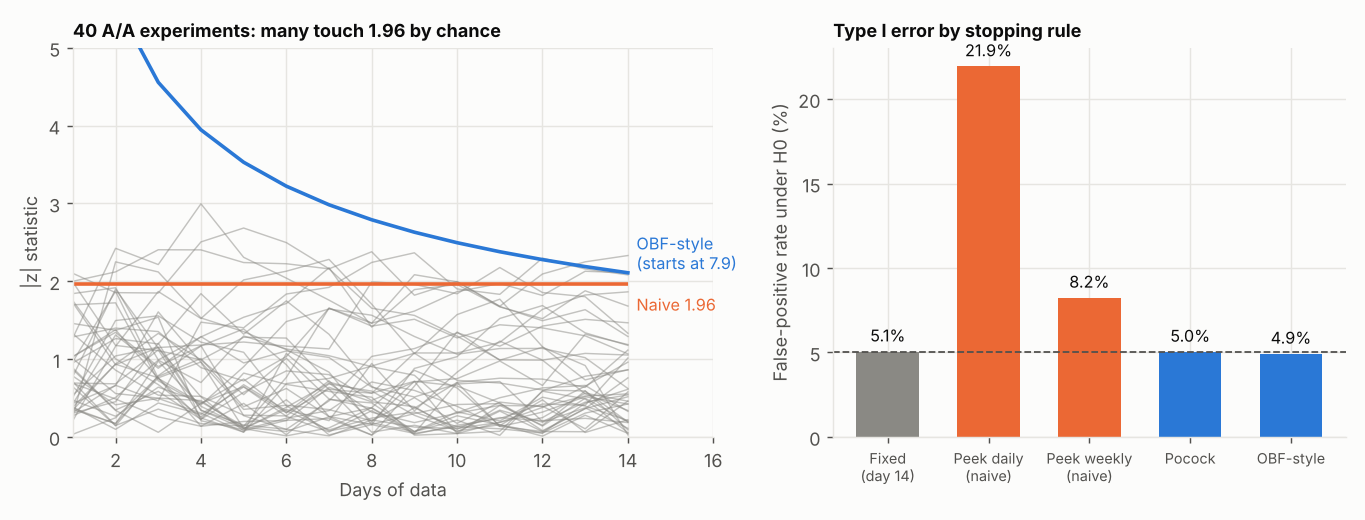

In [7]:
k = json.load(open("../results/peeking.json"))
print({n: round(v, 3) for n, v in k["null"].items() if not n.startswith("avg")})
Image("../figures/peeking.png")

## 6. Segments and novelty
Segments are hypotheses; formal interaction test and multiple-testing correction are in `memo/02_decision_memo.md`.

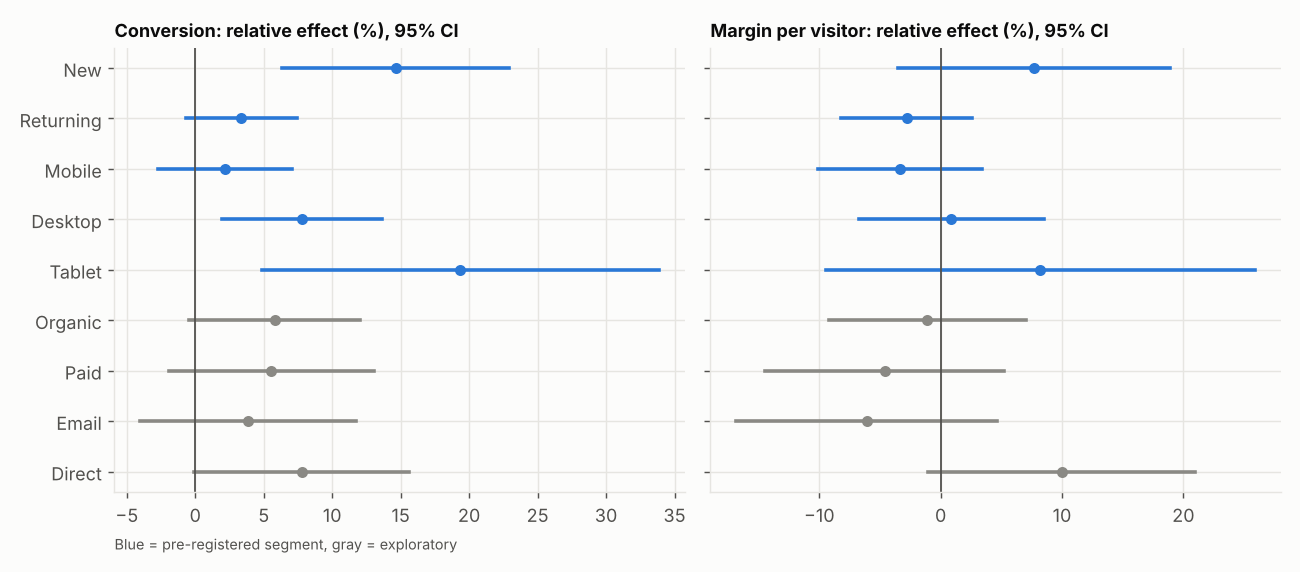

In [8]:
Image("../figures/segments_forest.png")

## 7. The decision
The rule from the design doc, applied to the results: conversion significantly up, margin CI lower bound above −2%, returns not significantly up.

In [9]:
A = json.load(open("../results/analysis.json"))
m = {r["metric"]: r for r in A["metrics"]}
cv_, mp_, rt_ = m["Conversion rate"], m["Margin per visitor"], m["Return rate (per order)"]
conv_up = cv_["p_holm"] < 0.05 and cv_["diff"] > 0
margin_ok = mp_["rel_lo"] > -0.02
returns_ok = not (rt_["p_holm"] < 0.05 and rt_["diff"] > 0)
print(f"conversion significantly up (Holm): {conv_up}  ({cv_['rel']:+.1%}, p={cv_['p_holm']:.3f})")
print(f"margin CI lower bound above -2%:    {margin_ok}  (lower bound {mp_['rel_lo']:+.1%})")
print(f"returns not significantly up:       {returns_ok}")
print("DECISION:", "ship to everyone" if conv_up and margin_ok and returns_ok else "do not ship to everyone; targeted follow-up")

conversion significantly up (Holm): True  (+5.7%, p=0.007)
margin CI lower bound above -2%:    False  (lower bound -5.5%)
returns not significantly up:       True
DECISION: do not ship to everyone; targeted follow-up


## 8. Reveal: how close were we?
Because the data is simulated, we know the truth.

true conversion lift (window / steady state): +6.6% / +5.0%
true margin/visitor effect (window / steady state): +1.5% / +0.1%


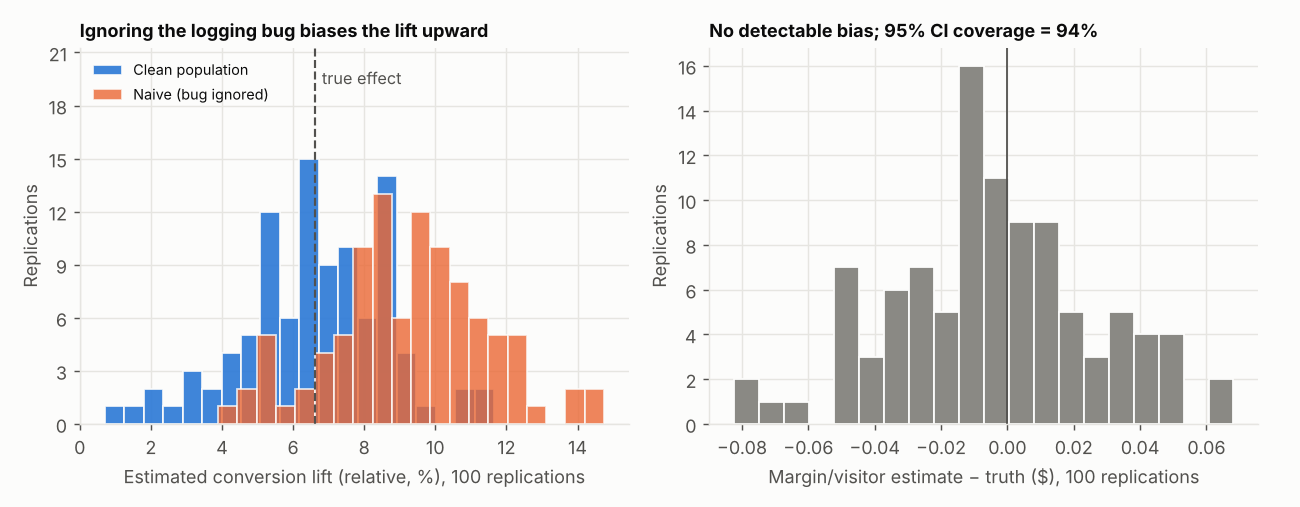

In [10]:
R = json.load(open("../results/reveal.json"))["true_effects"]
print(f"true conversion lift (window / steady state): {R['clean_window']['conv_rel']:+.1%} / {R['clean_steady']['conv_rel']:+.1%}")
print(f"true margin/visitor effect (window / steady state): {R['clean_window']['margin_rel']:+.1%} / {R['clean_steady']['margin_rel']:+.1%}")
Image("../figures/montecarlo_coverage.png")